In [31]:
from doctest import debug, debug_script
from hashlib import algorithms_available

%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from skimage.restoration import unwrap_phase

# Point sys.path to the repository root
repo_root = Path.cwd().parent
if str(repo_root) not in sys.path:
    sys.path.append(str(repo_root))

# Import the PhaseMapGenerator (assuming you saved it in src/phase_map_generator.py)
# from src.phase_map_generator import PhaseMapGenerator
import config
import src.phase_extraction as pe
import src.calibration as calib
import src.cylindrical_analysis as ca

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Phase extraction

Unsupported data type for _convert.
Unsupported data type for _convert.


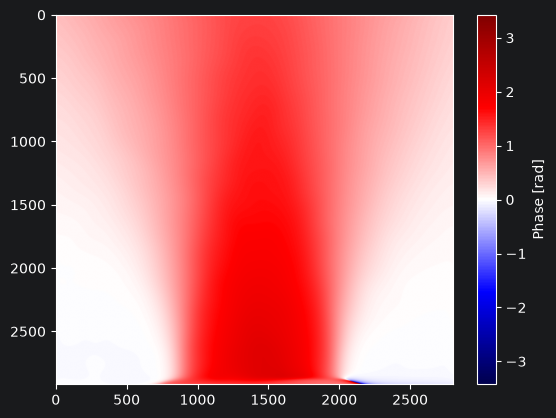

In [37]:
hdf5_path = r"C:\Users\vmlab\Documents\data\files\2026\05\13\Ar_10bar"

roi = [2000, -1, 1000, 4000]  # [x_start, x_end, y_start, y_end]
ref_img, exp_img, ref_roi, exp_roi = pe.get_interferometry_images(hdf5_path, roi=roi)

ref_fourier_shifted = pe.get_fourier(ref_roi)
exp_fourier_shifted = pe.get_fourier(exp_roi)

dominant_frequency = pe.get_dominant_frequency(ref_fourier_shifted, debug=False)

delta_phase_wrapped = pe.get_delta_phase_wrapped(ref_fourier_shifted, exp_fourier_shifted, dominant_frequency,
                                                 debug=False)
ref_edge, *_ = calib.estimate_nozzle_edge(ref_roi)
x_left, x_right = calib.detect_nozzle_x_range(ref_roi, ref_edge)
x_left += 50
x_right -= 50
calibrated_phase, _ = calib.calibrate_phase(delta_phase_wrapped, ref_edge, x_left, x_right, debug=True)

# Constants
NOZZLE_WIDTH_MM = 3.2
px_to_mm = calib.calculate_px_to_mm(x_left, x_right, NOZZLE_WIDTH_MM)


# density calculation

In [40]:
phi_cropped = ca.crop_and_format_phase_map(calibrated_phase_perp, nozzle_edge_y=ref_edge, px_to_mm=px_to_mm, max_height_mm=6.0)

center_x = 0.5 * (x_left + x_right)
density_cm3, r_mm, y_mm = ca.phase_to_density(phi_cropped, px_to_mm=px_to_mm, center_x = center_x)

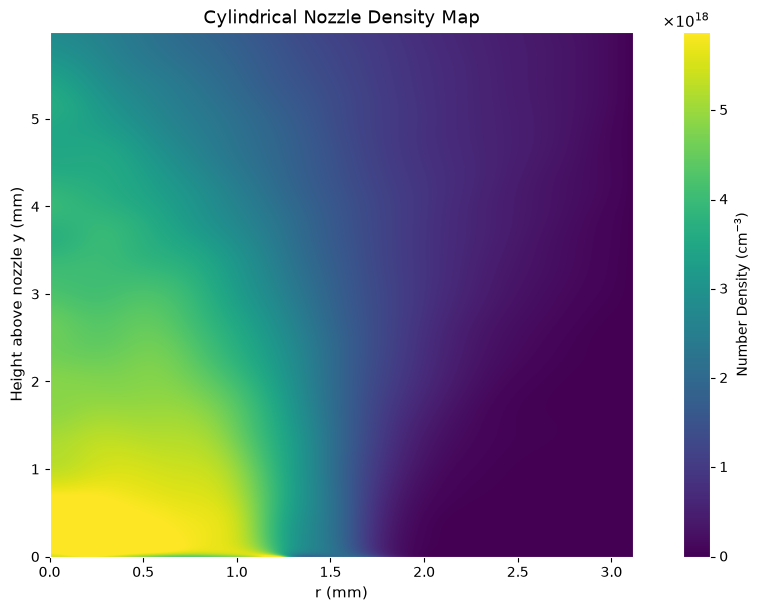

In [43]:
ca.plot_density_map(density_cm3, y_mm=y_mm, r_mm=r_mm)